# `tl.ripley_l` vs `astropy.stats.RipleysKEstimator`

Compares astrolabe's Ripley's L against astropy's reference implementation. `tl.ripley_l` deliberately skips edge correction (a documented design choice - boundary cells are undercounted and `L_obs` reflects that bias rather than correcting for it), so this notebook uses astropy's matching `mode='none'` for an apples-to-apples comparison.


In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import time
import numpy as np
import astrolabe as ab
from astropy.stats import RipleysKEstimator


INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


## Dataset

`ab.datasets.xenium_tiny()` with Leiden clusters as the point-pattern grouping - Ripley's L asks, for each cluster, whether its cells are more clustered or more dispersed in space than complete spatial randomness would predict.


In [2]:
mdata = ab.datasets.xenium_tiny()
ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)
ab.pp.highly_variable_genes(mdata)
ab.tl.pca(mdata)
ab.tl.transcriptional_neighbors(mdata)
ab.tl.cluster(mdata, resolution=0.5)

adata = mdata["xenium"]
adata


INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\astropy_stats\.astrolabe_cache\datasets\xenium_tiny\outs


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\io\_xenium.py:870: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  adata.obsm[obsm_key] = ak.Array(
INFO:astrolabe.io._xenium:Loaded 358 cells × 520 features (115 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\astropy_stats\.astrolabe_cache\datasets\xenium_tiny\outs\transcripts.parquet


INFO:astrolabe.io._xenium:Loaded 20999 transcript detections


INFO:astrolabe.pipeline:filter_xenium: 358 cells × 520 genes


...

INFO:astrolabe.pipeline:  [remove_controls] 370 → 255 genes  (removed 115, 31.1%)


INFO:astrolabe.pipeline:filter_xenium: done — 328 cells × 255 genes


INFO:astrolabe.tl._graph:transcriptional_neighbors: 328 cells -> uns['neighbors']


INFO:astrolabe.tl._cluster:cluster (leiden, res=0.50): 4 clusters


AnnData object with n_obs × n_vars = 328 × 255
    obs: 'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'nucleus_count', 'unassigned_codeword_total', 'deprecated_codeword_total', 'genomic_control_probe_total', 'negative_control_codeword_total', 'negative_control_probe_total', 'any_negative_control_probe_total', 'n_unassigned_codewords', 'n_deprecated_codewords', 'n_genomic_control_probes', 'n_negative_control_codewords', 'n_negative_control_probes', 'n_any_negative_control_probes', 'pct_unassigned_codewords', 'pct_deprecated_codewords', 'pct_genomic_control_probes', 'pct_negative_control_codewords', 'pct_negative_control_probes', 'pct_any_negative_control_probes', 'pct_counts_control', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'nucleus_to_cell_area_ratio', 'has_nucleus', 'total_counts_norm', 'leiden'

## Astrolabe: `tl.ripley_l`

`n_perms=0` skips the CSR permutation envelope, which has no astropy equivalent - this notebook only validates the deterministic `L_obs` curve.


In [3]:
support = 200
_t0 = time.perf_counter()
results = ab.tl.ripley_l(mdata, groupby="leiden", support=support, n_perms=0)
t_astro_s = time.perf_counter() - _t0
print(f"astrolabe runtime: {t_astro_s:.4f}s")
groups = list(results.keys())
groups


INFO:astrolabe.tl._spatial_stats:ripley_l: 4 groups, support=200, n_perms=0


INFO:astrolabe.tl._spatial_stats:ripley_l: done — 4 groups


astrolabe runtime: 0.0063s


['0', '1', '3', '2']

## Reference: `astropy.stats.RipleysKEstimator`, same shared tissue-wide window

Replicates astrolabe's window convention: one radii grid and study-region window computed from the full dataset's bounding box and shared across every group, rather than each group's own. `RipleysKEstimator.Lfunction` returns the raw `L(r) = sqrt(K(r)/pi)`, so it's detrended by subtracting `r` to match astrolabe's `L(r) - r` convention.


In [4]:
coords = np.asarray(adata.obsm["spatial"], dtype=np.float64)
window_min = coords.min(axis=0)
window_max = coords.max(axis=0)
xy_range = window_max - window_min
max_r = float(min(xy_range)) / 4.0
radii = np.linspace(0.0, max_r, support)
area = float((window_max[0] - window_min[0]) * (window_max[1] - window_min[1]))

estimator = RipleysKEstimator(
    area=area,
    x_min=window_min[0], x_max=window_max[0],
    y_min=window_min[1], y_max=window_max[1],
)

_t0 = time.perf_counter()
l_ref = {}
for g in groups:
    mask = (adata.obs["leiden"] == g).to_numpy()
    pts = coords[mask]
    l_raw = estimator.Lfunction(pts, radii, mode="none")
    l_ref[g] = l_raw - radii  # detrend to match astrolabe's L(r) - r
t_ref_s = time.perf_counter() - _t0
print(f"reference runtime: {t_ref_s:.4f}s")


reference runtime: 0.0072s


## Agreement


Pearson r = 1.000000, max |astrolabe - astropy| = 0.00e+00
Runtime: astrolabe 0.0063s vs astropy 0.0072s (1.1x astrolabe faster)


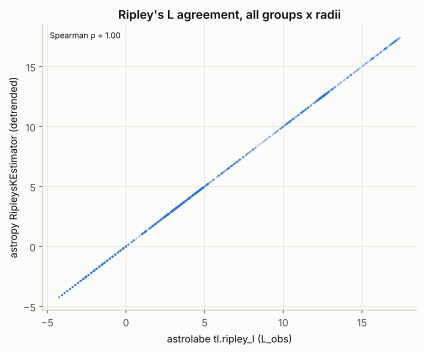

In [5]:
astro_vals = np.concatenate([results[g]["L_obs"].to_numpy() for g in groups])
ref_vals = np.concatenate([l_ref[g] for g in groups])

r = np.corrcoef(astro_vals, ref_vals)[0, 1]
max_abs_diff = float(np.abs(astro_vals - ref_vals).max())
print(f"Pearson r = {r:.6f}, max |astrolabe - astropy| = {max_abs_diff:.2e}")
print(f"Runtime: astrolabe {t_astro_s:.4f}s vs astropy {t_ref_s:.4f}s "
      f"({max(t_astro_s, t_ref_s) / min(t_astro_s, t_ref_s):.1f}x astrolabe {'faster' if t_astro_s < t_ref_s else 'slower'})")

panel = ab.pl.scatter(
    adata, x=astro_vals, y=ref_vals, annotate_corr=True,
    xlabel="astrolabe tl.ripley_l (L_obs)", ylabel="astropy RipleysKEstimator (detrended)",
    title="Ripley's L agreement, all groups x radii",
)
panel.show()


## Interpretation

Both compute the same no-edge-correction K(r) over the same shared window, so the result should land on the `y = x` line to floating-point precision. A visible deviation would point to a window-construction mismatch (per-group vs. shared) rather than the K(r) formula itself.
